# 04 · Modelado: machine learning clásico

**Fase 4 de CRISP-DM.** Clasificar la calidad (*good / regular / bad*) a partir de **80 características
manuales calculadas solo sobre la fruta segmentada** (`src/features/extraccion.py`: color HSV/Lab,
histogramas, manchas relativas a la propia fruta, textura LBP/GLCM/bordes y forma).

Protocolo (para que los resultados sean comparables y sin fuga):
- Entrenamiento y búsqueda de hiperparámetros: `train`, con `GridSearchCV` y **`StratifiedGroupKFold` (5 folds,
  grupos = misma toma)**, métrica **macro-F1**.
- Selección del modelo: `val`.
- `test` y `test_propias` **no se usan aquí**: se evalúan una sola vez en el notebook 05, junto con la CNN.

In [1]:
import sys, time, json
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold, learning_curve
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.inspection import permutation_importance

from src.config import QUALITY_CLASSES, FRUITS, SEED, DATA_DIR, CHECKPOINTS_DIR, RESULTS_DIR
from src.data.carga import cargar_splits
from src.features.extraccion import NOMBRES
from src.models.clasicos import lineas_base, modelos_y_rejillas
from src.evaluation.metricas import resumen, tabla

FIG_DIR = ROOT / "docs" / "figures"
CHECKPOINTS_DIR.mkdir(parents=True, exist_ok=True); RESULTS_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.bbox": "tight", "svg.fonttype": "none"})
COLS = ["macro-F1", "acc. balanceada", "kappa", "F1 good", "F1 regular", "F1 bad", "recall regular", "recall bad"]

df = cargar_splits()
def cargar_X(nombre):
    feats = pd.read_csv(DATA_DIR / f"features_{nombre}.csv").set_index("filename")
    return feats.loc[df.filename, NOMBRES].values.astype(np.float32)

X_all = cargar_X("fruta")
tr, va = (df.split == "train").values, (df.split == "val").values
Xtr, ytr, gtr = X_all[tr], df.y.values[tr], df.grupo.values[tr]
Xva, yva = X_all[va], df.y.values[va]
w_tr = compute_sample_weight("balanced", ytr)        # pesos para XGBoost
print(f"train {Xtr.shape} | val {Xva.shape} | pesos por clase:",
      dict(zip(QUALITY_CLASSES, np.round([w_tr[ytr == k][0] for k in range(3)], 2))))
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)

train (3884, 80) | val (917, 80) | pesos por clase: {'good': np.float64(0.65), 'regular': np.float64(8.87), 'bad': np.float64(0.75)}


## 1. Líneas base

Un clasificador que no mira la imagen. Cualquier modelo útil debe superarlas claramente en macro-F1.

In [2]:
res_val = {}
for nombre, m in lineas_base().items():
    m.fit(Xtr, ytr)
    res_val[nombre] = resumen(yva, m.predict(Xva))
tabla(res_val, COLS)

,macro-F1,acc. balanceada,kappa,F1 good,F1 regular,F1 bad,recall regular,recall bad
Dummy (clase mayoritaria),0.216,0.333,0.000,0.648,0.000,0.000,0.000,0.000
Dummy (aleatorio estratificado),0.311,0.311,-0.058,0.459,0.031,0.442,0.031,0.436


## 2. Búsqueda de hiperparámetros (GridSearchCV + validación cruzada por grupos)

Cada modelo se ajusta con su rejilla (`src/models/clasicos.py`) maximizando el macro-F1 medio de los 5 folds.
Se guardan también los puntajes en entrenamiento para diagnosticar sobreajuste.

In [3]:
busquedas, filas_cv = {}, []
for nombre, (pipe, rejilla) in modelos_y_rejillas(pesos_clase=True).items():
    t0 = time.time()
    gs = GridSearchCV(pipe, rejilla, scoring="f1_macro", cv=cv, n_jobs=-1 if nombre != "Random Forest" else 1,
                      return_train_score=True, refit=True)
    extra = {"modelo__sample_weight": w_tr} if nombre == "XGBoost" else {}
    gs.fit(Xtr, ytr, groups=gtr, **extra)
    busquedas[nombre] = gs
    i = gs.best_index_
    filas_cv.append({"modelo": nombre, "combinaciones": len(gs.cv_results_["params"]),
                     "mejores hiperparámetros": {k.replace("modelo__", ""): v for k, v in gs.best_params_.items()},
                     "macro-F1 train": gs.cv_results_["mean_train_score"][i],
                     "macro-F1 CV": gs.best_score_, "desv. CV": gs.cv_results_["std_test_score"][i],
                     "tiempo (s)": round(time.time() - t0)})
    print(f"{nombre:22s} CV macro-F1 = {gs.best_score_:.3f}  ({time.time() - t0:.0f} s)")
cv_tabla = pd.DataFrame(filas_cv).set_index("modelo")
cv_tabla.round(3)

Regresión logística    CV macro-F1 = 0.600  (7 s)


KNN                    CV macro-F1 = 0.654  (5 s)


SVM (RBF)              CV macro-F1 = 0.716  (15 s)


Random Forest          CV macro-F1 = 0.684  (227 s)


XGBoost                CV macro-F1 = 0.688  (249 s)


,combinaciones,mejores hiperparámetros,macro-F1 train,macro-F1 CV,desv. CV,tiempo (s)
modelo,,,,,,
Regresión logística,4,{'C': 10},0.662,0.600,0.008,7
KNN,16,"{'n_neighbors': 5, 'p': 1, 'weights': 'uniform'}",0.778,0.654,0.023,5
SVM (RBF),20,"{'C': 30, 'gamma': 0.003}",0.857,0.716,0.025,15
Random Forest,18,"{'max_depth': 12, 'max_features': 'sqrt', 'min...",0.936,0.684,0.033,227
XGBoost,12,"{'learning_rate': 0.03, 'max_depth': 5, 'min_c...",0.988,0.688,0.021,249


In [4]:
# Rejilla completa probada (para documentar en el informe)
rejillas = []
for nombre, gs in busquedas.items():
    r = pd.DataFrame(gs.cv_results_)[["params", "mean_train_score", "mean_test_score", "std_test_score", "rank_test_score"]]
    r.insert(0, "modelo", nombre)
    rejillas.append(r)
rejillas = pd.concat(rejillas)
rejillas["params"] = rejillas.params.map(lambda p: json.dumps({k.replace("modelo__", ""): v for k, v in p.items()}))
rejillas.to_csv(RESULTS_DIR / "ml_clasico_rejillas.csv", index=False)
print("Rejillas guardadas en experiments/results/ml_clasico_rejillas.csv")
rejillas.sort_values(["modelo", "rank_test_score"]).groupby("modelo").head(3).round(3)

Rejillas guardadas en experiments/results/ml_clasico_rejillas.csv


,modelo,params,mean_train_score,mean_test_score,std_test_score,rank_test_score
0,KNN,"{""n_neighbors"": 5, ""p"": 1, ""weights"": ""uniform""}",0.778,0.654,0.023,1
1,KNN,"{""n_neighbors"": 5, ""p"": 1, ""weights"": ""distance""}",1.000,0.650,0.022,2
2,KNN,"{""n_neighbors"": 5, ""p"": 2, ""weights"": ""uniform""}",0.777,0.644,0.021,3
8,Random Forest,"{""max_depth"": 12, ""max_features"": ""sqrt"", ""min...",0.936,0.684,0.033,1
14,Random Forest,"{""max_depth"": 20, ""max_features"": ""sqrt"", ""min...",0.942,0.682,0.037,2
2,Random Forest,"{""max_depth"": null, ""max_features"": ""sqrt"", ""m...",0.942,0.682,0.036,3
3,Regresión logística,"{""C"": 10}",0.662,0.600,0.008,1
2,Regresión logística,"{""C"": 1}",0.649,0.592,0.011,2
1,Regresión logística,"{""C"": 0.1}",0.635,0.585,0.009,3
17,SVM (RBF),"{""C"": 30, ""gamma"": 0.003}",0.857,0.716,0.025,1


## 3. Comparación en validación

In [5]:
for nombre, gs in busquedas.items():
    res_val[nombre] = resumen(yva, gs.predict(Xva))
comp = tabla(res_val, COLS)
comp.to_csv(RESULTS_DIR / "ml_clasico_val.csv")
comp

,macro-F1,acc. balanceada,kappa,F1 good,F1 regular,F1 bad,recall regular,recall bad
Dummy (clase mayoritaria),0.216,0.333,0.000,0.648,0.000,0.000,0.000,0.000
Dummy (aleatorio estratificado),0.311,0.311,-0.058,0.459,0.031,0.442,0.031,0.436
Regresión logística,0.602,0.654,0.599,0.800,0.153,0.854,0.406,0.829
KNN,0.647,0.644,0.819,0.912,0.093,0.937,0.062,0.957
SVM (RBF),0.727,0.780,0.802,0.903,0.333,0.944,0.531,0.942
Random Forest,0.631,0.627,0.745,0.873,0.118,0.902,0.094,0.906
XGBoost,0.647,0.645,0.821,0.914,0.087,0.940,0.062,0.957


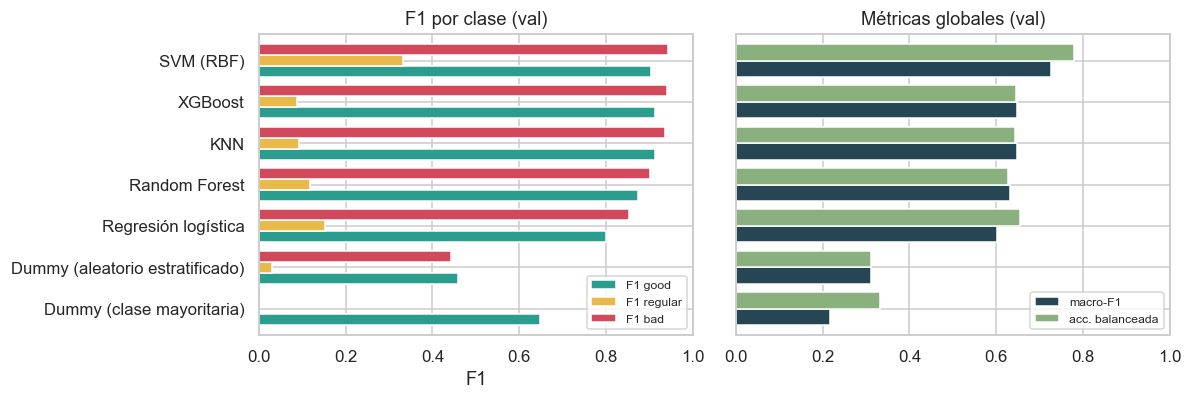

Mejor modelo en val (macro-F1): SVM (RBF)


In [6]:
orden = comp.sort_values("macro-F1").index
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
comp.loc[orden, ["F1 good", "F1 regular", "F1 bad"]].plot.barh(
    ax=axes[0], color=["#2a9d8f", "#e9b949", "#d1495b"], width=0.8)
axes[0].set(title="F1 por clase (val)", xlabel="F1", xlim=(0, 1)); axes[0].legend(loc="lower right", fontsize=8)
comp.loc[orden, ["macro-F1", "acc. balanceada"]].plot.barh(ax=axes[1], color=["#264653", "#8ab17d"], width=0.8)
axes[1].set(title="Métricas globales (val)", xlabel="", xlim=(0, 1)); axes[1].legend(loc="lower right", fontsize=8)
fig.tight_layout(); fig.savefig(FIG_DIR / "ml_comparacion_val.svg"); plt.show()

modelos_ml = [m for m in busquedas]
mejor = comp.loc[modelos_ml, "macro-F1"].idxmax()
print("Mejor modelo en val (macro-F1):", mejor)

## 4. Sobreajuste: entrenamiento vs validación cruzada

La brecha entre el macro-F1 en los folds de entrenamiento y en los de validación indica cuánto memoriza el
modelo. Para el mejor modelo se traza además la **curva de aprendizaje** (macro-F1 vs. tamaño de entrenamiento).

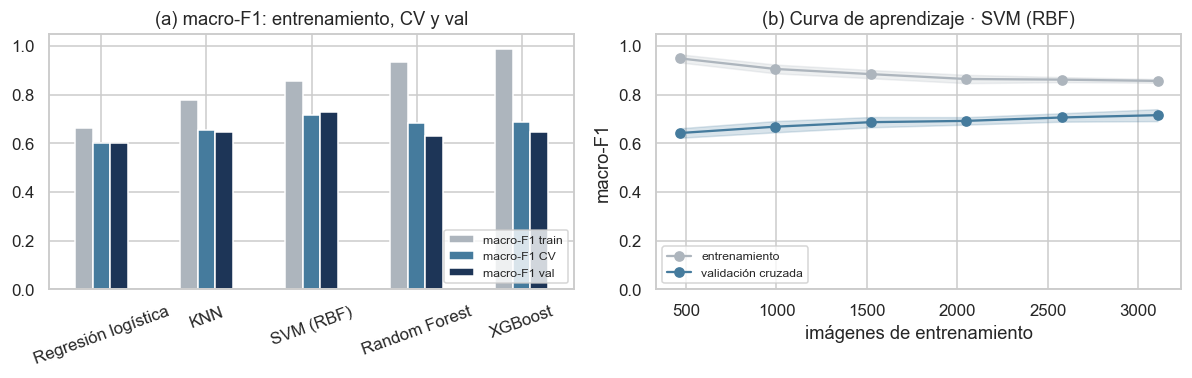

,macro-F1 train,macro-F1 CV,macro-F1 val,brecha train-CV
modelo,,,,
Regresión logística,0.662,0.600,0.602,0.062
KNN,0.778,0.654,0.647,0.124
SVM (RBF),0.857,0.716,0.727,0.141
Random Forest,0.936,0.684,0.631,0.252
XGBoost,0.988,0.688,0.647,0.300


In [7]:
brecha = cv_tabla[["macro-F1 train", "macro-F1 CV"]].astype(float)
brecha["macro-F1 val"] = comp.loc[brecha.index, "macro-F1"]
brecha["brecha train-CV"] = brecha["macro-F1 train"] - brecha["macro-F1 CV"]

est = busquedas[mejor].best_estimator_
extra = {"modelo__sample_weight": w_tr} if mejor == "XGBoost" else {}
tam, sc_tr, sc_cv = learning_curve(est, Xtr, ytr, groups=gtr, cv=cv, scoring="f1_macro",
                                   train_sizes=np.linspace(0.15, 1.0, 6), n_jobs=-1, shuffle=True,
                                   random_state=SEED, params=extra)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
brecha[["macro-F1 train", "macro-F1 CV", "macro-F1 val"]].plot.bar(ax=axes[0], rot=20, color=["#adb5bd", "#457b9d", "#1d3557"])
axes[0].set(title="(a) macro-F1: entrenamiento, CV y val", ylim=(0, 1.05), xlabel="")
axes[0].legend(fontsize=8, loc="lower right")
for s, c, lab in [(sc_tr, "#adb5bd", "entrenamiento"), (sc_cv, "#457b9d", "validación cruzada")]:
    axes[1].plot(tam, s.mean(1), "o-", c=c, label=lab)
    axes[1].fill_between(tam, s.mean(1) - s.std(1), s.mean(1) + s.std(1), color=c, alpha=0.2)
axes[1].set(title=f"(b) Curva de aprendizaje · {mejor}", xlabel="imágenes de entrenamiento", ylabel="macro-F1", ylim=(0, 1.05))
axes[1].legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG_DIR / "ml_sobreajuste.svg"); plt.show()
brecha.round(3)

## 5. Análisis del mejor modelo en validación

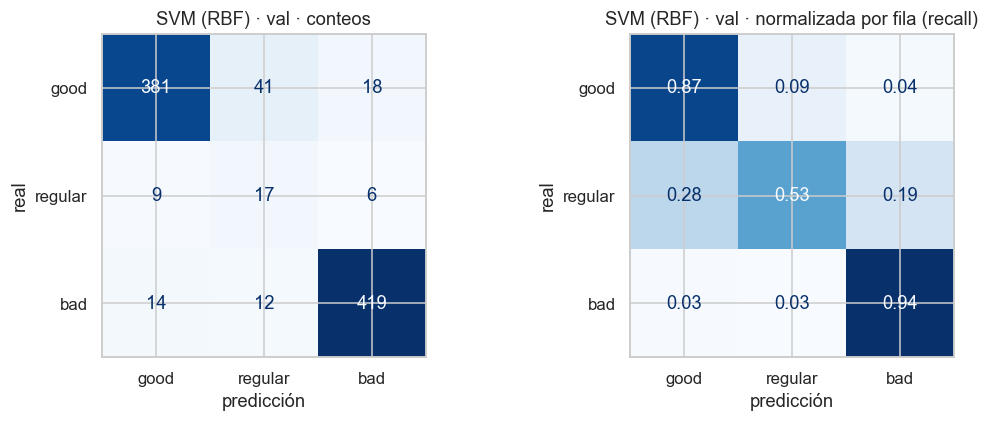

,macro-F1,acc. balanceada,kappa,F1 good,F1 regular,F1 bad,recall regular,recall bad
apple,0.658,0.671,0.757,0.897,0.154,0.924,0.231,0.909
banana,0.852,0.961,0.908,0.938,0.621,0.996,1.000,1.000
orange,0.702,0.759,0.772,0.888,0.294,0.922,0.500,0.928


In [8]:
pred_va = est.predict(Xva)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, norm, t in [(axes[0], None, "conteos"), (axes[1], "true", "normalizada por fila (recall)")]:
    ConfusionMatrixDisplay(confusion_matrix(yva, pred_va, normalize=norm), display_labels=QUALITY_CLASSES).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format=".2f" if norm else "d")
    ax.set(title=f"{mejor} · val · {t}", xlabel="predicción", ylabel="real")
fig.tight_layout(); fig.savefig(FIG_DIR / "ml_confusion_val.svg"); plt.show()

dva = df[va].assign(pred=pred_va)
pd.DataFrame({f: resumen(g.y, g.pred) for f, g in dva.groupby("fruit")}).T[COLS].round(3)

## 6. Ablaciones

1. **Pesos de clase**: el mismo tipo de modelo, con los mejores hiperparámetros, sin compensar el desbalance.
2. **Fruta vs imagen completa**: las mismas características calculadas sobre toda la imagen (con fondo). En
   `val` (que también es Kaggle) la imagen completa puede rendir igual o mejor gracias al atajo del fondo; la
   prueba que importa es `test_propias` (notebook 05), donde el fondo cambia.

In [9]:
from sklearn.base import clone
abl = {}
abl[f"{mejor} (fruta, con pesos)"] = res_val[mejor]

sin_pesos = modelos_y_rejillas(pesos_clase=False)[mejor][0].set_params(**busquedas[mejor].best_params_)
sin_pesos.fit(Xtr, ytr)
abl[f"{mejor} (fruta, sin pesos)"] = resumen(yva, sin_pesos.predict(Xva))

X_comp = cargar_X("completa")
completo = clone(est).fit(X_comp[tr], ytr, **extra)
abl[f"{mejor} (imagen completa, con pesos)"] = resumen(yva, completo.predict(X_comp[va]))
tabla(abl, COLS)

,macro-F1,acc. balanceada,kappa,F1 good,F1 regular,F1 bad,recall regular,recall bad
"SVM (RBF) (fruta, con pesos)",0.727,0.780,0.802,0.903,0.333,0.944,0.531,0.942
"SVM (RBF) (fruta, sin pesos)",0.630,0.640,0.859,0.935,0.000,0.953,0.000,0.966
"SVM (RBF) (imagen completa, con pesos)",0.731,0.776,0.817,0.908,0.330,0.954,0.500,0.953


## 7. ¿Qué características usa el modelo?

Importancia por permutación en `val`: cuánto cae el macro-F1 si se barajan los valores de una característica
(rompiendo su relación con la etiqueta). A diferencia de la importancia interna de los árboles, sirve para
cualquier modelo y se mide en datos no usados para entrenar.

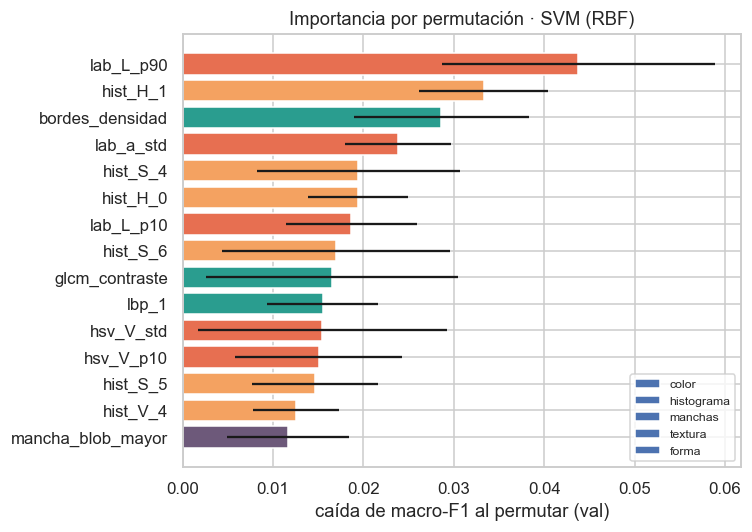

grupo
hist      0.161
lab       0.095
hsv       0.047
bordes    0.029
glcm      0.004
forma     0.002
lbp      -0.009
mancha   -0.009
Name: media, dtype: float64

In [10]:
imp = permutation_importance(est, Xva, yva, scoring="f1_macro", n_repeats=10, random_state=SEED, n_jobs=-1)
imp = pd.DataFrame({"caracteristica": NOMBRES, "media": imp.importances_mean, "desv": imp.importances_std}) \
        .sort_values("media", ascending=False)
top = imp.head(15).iloc[::-1]
grupo = top.caracteristica.str.split("_").str[0].map(
    {"hsv": "color", "lab": "color", "hist": "histograma", "mancha": "manchas", "lbp": "textura",
     "glcm": "textura", "bordes": "textura", "forma": "forma"})
paleta = {"color": "#e76f51", "histograma": "#f4a261", "manchas": "#6d597a", "textura": "#2a9d8f", "forma": "#264653"}
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(top.caracteristica, top.media, xerr=top.desv, color=grupo.map(paleta))
for g, c in paleta.items():
    ax.barh([], [], color=c, label=g)
ax.legend(fontsize=8, loc="lower right"); ax.set(xlabel="caída de macro-F1 al permutar (val)", title=f"Importancia por permutación · {mejor}")
fig.tight_layout(); fig.savefig(FIG_DIR / "ml_importancia.svg"); plt.show()
imp.assign(grupo=imp.caracteristica.str.split("_").str[0]).groupby("grupo").media.sum().sort_values(ascending=False).round(3)

## 8. Guardar los modelos

Se guardan todos los modelos ajustados (para compararlos en `test` en el notebook 05) y, para el mejor, una
versión con probabilidades (la app muestra la confianza) y la versión entrenada con la imagen completa (para
el experimento del atajo). Los `.joblib` no se versionan (`.gitignore`): se regeneran ejecutando este notebook.

In [11]:
ARCHIVO = {"Regresión logística": "logistica", "KNN": "knn", "SVM (RBF)": "svm",
           "Random Forest": "random_forest", "XGBoost": "xgboost"}
for nombre, gs in busquedas.items():
    joblib.dump(gs.best_estimator_, CHECKPOINTS_DIR / f"ml_{ARCHIVO[nombre]}.joblib")
if mejor == "SVM (RBF)":
    final = clone(est).set_params(modelo__probability=True).fit(Xtr, ytr)
else:
    final = est
joblib.dump(final, CHECKPOINTS_DIR / "ml_mejor.joblib")
joblib.dump(completo, CHECKPOINTS_DIR / "ml_mejor_imagen_completa.joblib")
json.dump({"mejor": mejor, "hiperparametros": {k.replace("modelo__", ""): v for k, v in busquedas[mejor].best_params_.items()},
           "caracteristicas": "features_fruta (80)", "seleccion": "macro-F1 en val"},
          open(RESULTS_DIR / "ml_clasico_mejor.json", "w"), indent=2, default=str)
print(sorted(p.name for p in CHECKPOINTS_DIR.glob("ml_*.joblib")))

['ml_knn.joblib', 'ml_mejor.joblib', 'ml_mejor_imagen_completa.joblib', 'ml_random.joblib', 'ml_regresión.joblib', 'ml_svm.joblib', 'ml_xgboost.joblib']


## 9. Conclusiones

1. **Todos los modelos superan claramente a la línea base.** El clasificador trivial logra macro-F1 0,22
   (clase mayoritaria) y 0,31 (aleatorio); el mejor modelo, 0,73 en `val`.
2. **El mejor modelo es el SVM con kernel RBF** (C = 30, γ = 0,003): macro-F1 0,716 ± 0,025 en validación
   cruzada por grupos y 0,727 en `val`, con F1 de 0,90 (*good*) y 0,94 (*bad*). La cercanía entre CV y `val`
   indica que la estimación es estable. Le siguen XGBoost (0,69 CV), Random Forest (0,68), KNN (0,65) y
   regresión logística (0,60). Que el SVM gane a la regresión logística muestra que la frontera entre clases
   no es lineal en el espacio de características.
3. **"regular" sigue siendo el problema.** Incluso el SVM logra solo F1 0,33 (recall 0,53, precisión ~0,25):
   detecta la mitad de las *regular*, pero a costa de falsas alarmas. Los demás modelos casi no la predicen
   (recall ≤ 0,41). Por fruta, el banano va bien (9 de 9 *regular* detectadas) y la manzana mal (recall 0,23);
   con 9–13 ejemplos por fruta en `val`, estas cifras tienen mucha incertidumbre.
4. **Los pesos de clase son imprescindibles.** Sin ellos, el mismo SVM nunca predice *regular* (recall 0) y el
   macro-F1 baja de 0,73 a 0,63, aunque el kappa sube (0,86): las métricas dominadas por las clases grandes
   esconden el fallo en la clase minoritaria. Por eso se usa macro-F1.
5. **Sobreajuste.** Los árboles memorizan: XGBoost logra 0,99 en entrenamiento frente a 0,69 en CV (brecha
   0,30) y Random Forest 0,94 frente a 0,68. El SVM tiene una brecha menor (0,86 frente a 0,72) y la regresión
   logística la menor (0,06), pero porque no tiene capacidad suficiente. Con ~3.900 imágenes y una clase de
   solo 146 ejemplos, los modelos más flexibles se ajustan al ruido.
6. **En `val`, la imagen completa rinde igual que la fruta sola** (0,731 frente a 0,727). Esto **no** quiere
   decir que el fondo no importe: `val` también es Kaggle y comparte sus fondos. La prueba del atajo es
   `test_propias` (notebook 05).
7. **El modelo se apoya sobre todo en el color.** Por importancia por permutación, los histogramas de tono,
   saturación y brillo y los estadísticos en Lab explican casi toda la caída de macro-F1; la densidad de bordes
   aporta algo; LBP y las características de manchas no aportan por encima de lo que ya dan los histogramas.
   Detectar defectos locales (lo que define a *regular*) probablemente requiere aprender características
   espaciales: es la motivación para la CNN.